
----- PSO NETWORK ROUTING -----
Source Node: A
Destination Node: H
Optimal Route: A -> B -> D -> E -> H
Minimum Routing Cost: 9.5
Total Distance: 12
Total Delay: 7


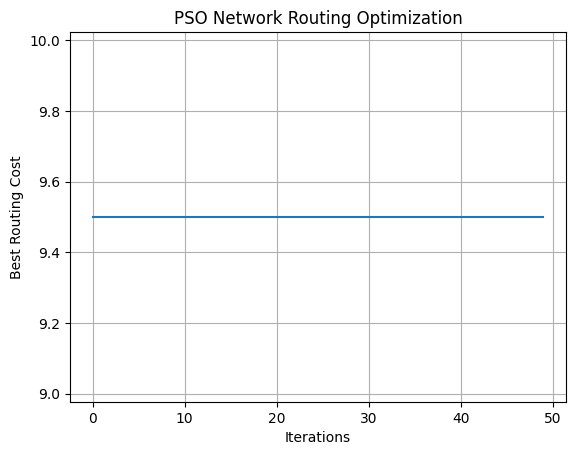

In [1]:

import random
import math

# --------------------------------
# 1. Create Network
# --------------------------------

network = {
    'A': {'B': (4, 2), 'C': (2, 3)},
    'B': {'A': (4, 2), 'D': (3, 2), 'E': (5, 4)},
    'C': {'A': (2, 3), 'D': (4, 2), 'F': (6, 3)},
    'D': {'B': (3, 2), 'C': (4, 2), 'E': (2, 1), 'G': (5, 3)},
    'E': {'B': (5, 4), 'D': (2, 1), 'H': (3, 2)},
    'F': {'C': (6, 3), 'G': (2, 1)},
    'G': {'D': (5, 3), 'F': (2, 1), 'H': (3, 2)},
    'H': {'E': (3, 2), 'G': (3, 2)}
}

source = 'A'
destination = 'H'

# --------------------------------
# 2. Generate All Possible Paths
# --------------------------------

def find_paths(node, destination, path=None):
    if path is None:
        path = []

    path = path + [node]

    if node == destination:
        return [path]

    paths = []

    for neighbor in network[node]:
        if neighbor not in path:
            new_paths = find_paths(
                neighbor, destination, path
            )
            paths.extend(new_paths)

    return paths


all_paths = find_paths(source, destination)

# --------------------------------
# 3. Fitness Function
# --------------------------------

def fitness(path):

    distance = 0
    delay = 0

    for i in range(len(path) - 1):

        d, t = network[path[i]][path[i + 1]]

        distance += d
        delay += t

    # Combined routing cost
    cost = 0.5 * distance + 0.5 * delay

    return cost


# --------------------------------
# 4. PSO Initialization
# --------------------------------

num_particles = 20
max_iterations = 50

w = 0.7
c1 = 1.5
c2 = 1.5

num_paths = len(all_paths)

positions = [
    random.uniform(0, num_paths - 1)
    for _ in range(num_particles)
]

velocities = [
    random.uniform(-1, 1)
    for _ in range(num_particles)
]

pbest = positions.copy()

pbest_fitness = [
    fitness(all_paths[round(p)])
    for p in positions
]

gbest_index = min(
    range(num_particles),
    key=lambda i: pbest_fitness[i]
)

gbest = pbest[gbest_index]
gbest_fitness = pbest_fitness[gbest_index]

convergence = []

# --------------------------------
# 5. PSO Optimization
# --------------------------------

for iteration in range(max_iterations):

    for i in range(num_particles):

        current_index = max(
            0, min(num_paths - 1, round(positions[i]))
        )

        current_fitness = fitness(
            all_paths[current_index]
        )

        # Update Personal Best
        if current_fitness < pbest_fitness[i]:

            pbest[i] = positions[i]
            pbest_fitness[i] = current_fitness

        # Update Global Best
        if current_fitness < gbest_fitness:

            gbest = positions[i]
            gbest_fitness = current_fitness

        # Random values
        r1 = random.random()
        r2 = random.random()

        # Update velocity
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest[i] - positions[i])
            + c2 * r2 * (gbest - positions[i])
        )

        # Update position
        positions[i] += velocities[i]

        # Boundary checking
        positions[i] = max(
            0, min(num_paths - 1, positions[i])
        )

    convergence.append(gbest_fitness)

# --------------------------------
# 6. Display Optimal Route
# --------------------------------

best_index = round(gbest)
best_path = all_paths[best_index]

print("\n----- PSO NETWORK ROUTING -----")

print("Source Node:", source)
print("Destination Node:", destination)

print("Optimal Route:",
      " -> ".join(best_path))

print("Minimum Routing Cost:", gbest_fitness)

# Calculate distance and delay
total_distance = 0
total_delay = 0

for i in range(len(best_path) - 1):

    d, t = network[best_path[i]][best_path[i + 1]]

    total_distance += d
    total_delay += t

print("Total Distance:", total_distance)
print("Total Delay:", total_delay)

# --------------------------------
# 7. Display Convergence Graph
# --------------------------------

try:
    import matplotlib.pyplot as plt

    plt.plot(convergence)
    plt.xlabel("Iterations")
    plt.ylabel("Best Routing Cost")
    plt.title("PSO Network Routing Optimization")
    plt.grid(True)
    plt.show()

except ImportError:
    print("Install matplotlib to display the graph.")
